<a href="https://colab.research.google.com/github/ziyadabdulla/Case-Studies-and-Assessments/blob/main/Intermediate_Assessment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
training_data = '/content/drive/MyDrive/DSA/Anitha miss/Analytics Vidhya/train_LZdllcl.csv'
testing_data = '/content/drive/MyDrive/DSA/Anitha miss/Analytics Vidhya/test_2umaH9m.csv'

df_train = pd.read_csv(training_data)
df_train.head()

,employee_id,department,region,education,gender,recruitment_channel,no_of_trainings,age,previous_year_rating,length_of_service,KPIs_met >80%,awards_won?,avg_training_score,is_promoted
0,65438,Sales & Marketing,region_7,Master's & above,f,sourcing,1,35,5.0,8,1,0,49,0
1,65141,Operations,region_22,Bachelor's,m,other,1,30,5.0,4,0,0,60,0
2,7513,Sales & Marketing,region_19,Bachelor's,m,sourcing,1,34,3.0,7,0,0,50,0
3,2542,Sales & Marketing,region_23,Bachelor's,m,other,2,39,1.0,10,0,0,50,0
4,48945,Technology,region_26,Bachelor's,m,other,1,45,3.0,2,0,0,73,0


In [3]:
df_train.shape

(54808, 14)

In [4]:
df_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 54808 entries, 0 to 54807
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   employee_id           54808 non-null  int64  
 1   department            54808 non-null  object 
 2   region                54808 non-null  object 
 3   education             52399 non-null  object 
 4   gender                54808 non-null  object 
 5   recruitment_channel   54808 non-null  object 
 6   no_of_trainings       54808 non-null  int64  
 7   age                   54808 non-null  int64  
 8   previous_year_rating  50684 non-null  float64
 9   length_of_service     54808 non-null  int64  
 10  KPIs_met >80%         54808 non-null  int64  
 11  awards_won?           54808 non-null  int64  
 12  avg_training_score    54808 non-null  int64  
 13  is_promoted           54808 non-null  int64  
dtypes: float64(1), int64(8), object(5)
memory usage: 5.9+ MB


In [5]:
df_train.describe()

,employee_id,no_of_trainings,age,previous_year_rating,length_of_service,KPIs_met >80%,awards_won?,avg_training_score,is_promoted
count,54808.000000,54808.000000,54808.000000,50684.000000,54808.000000,54808.000000,54808.000000,54808.000000,54808.000000
mean,39195.830627,1.253011,34.803915,3.329256,5.865512,0.351974,0.023172,63.386750,0.085170
std,22586.581449,0.609264,7.660169,1.259993,4.265094,0.477590,0.150450,13.371559,0.279137
min,1.000000,1.000000,20.000000,1.000000,1.000000,0.000000,0.000000,39.000000,0.000000
25%,19669.750000,1.000000,29.000000,3.000000,3.000000,0.000000,0.000000,51.000000,0.000000
50%,39225.500000,1.000000,33.000000,3.000000,5.000000,0.000000,0.000000,60.000000,0.000000
75%,58730.500000,1.000000,39.000000,4.000000,7.000000,1.000000,0.000000,76.000000,0.000000
max,78298.000000,10.000000,60.000000,5.000000,37.000000,1.000000,1.000000,99.000000,1.000000


In [6]:
df_train.duplicated().sum()

np.int64(0)

In [7]:
df_train.isnull().sum()

,0
employee_id,0
department,0
region,0
education,2409
gender,0
recruitment_channel,0
no_of_trainings,0
age,0
previous_year_rating,4124
length_of_service,0


In [8]:
# Impute 'education' with the mode
education_mode = df_train['education'].mode()[0]
df_train['education'] = df_train['education'].fillna(education_mode)

# Impute 'previous_year_rating' with the median
rating_median = df_train['previous_year_rating'].median()
df_train['previous_year_rating'] = df_train['previous_year_rating'].fillna(rating_median)

# Verify that there are no more missing values
print("Missing values after imputation:")
print(df_train.isnull().sum())

Missing values after imputation:
employee_id             0
department              0
region                  0
education               0
gender                  0
recruitment_channel     0
no_of_trainings         0
age                     0
previous_year_rating    0
length_of_service       0
KPIs_met >80%           0
awards_won?             0
avg_training_score      0
is_promoted             0
dtype: int64


In [9]:
df_train.head()

,employee_id,department,region,education,gender,recruitment_channel,no_of_trainings,age,previous_year_rating,length_of_service,KPIs_met >80%,awards_won?,avg_training_score,is_promoted
0,65438,Sales & Marketing,region_7,Master's & above,f,sourcing,1,35,5.0,8,1,0,49,0
1,65141,Operations,region_22,Bachelor's,m,other,1,30,5.0,4,0,0,60,0
2,7513,Sales & Marketing,region_19,Bachelor's,m,sourcing,1,34,3.0,7,0,0,50,0
3,2542,Sales & Marketing,region_23,Bachelor's,m,other,2,39,1.0,10,0,0,50,0
4,48945,Technology,region_26,Bachelor's,m,other,1,45,3.0,2,0,0,73,0


is_promoted
0    0.9148
1    0.0852
Name: proportion, dtype: float64


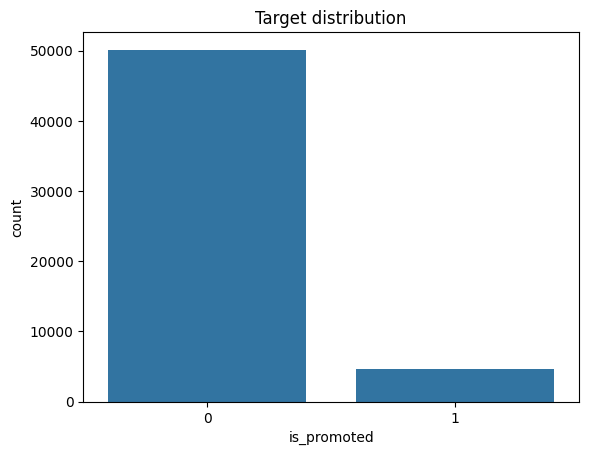

In [10]:
print(df_train['is_promoted'].value_counts(normalize=True).round(4))
sns.countplot(x='is_promoted', data=df_train)
plt.title('Target distribution')
plt.show()

In [11]:
def find_outliers(column):
    Q1 = df_train[column].quantile(0.25)
    Q3 = df_train[column].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    return df_train[(df_train[column] < lower) | (df_train[column] > upper)]
    return lower,upper

#outliers in age
outliers_age = find_outliers('age')
print("Outliers in age:",len(outliers_age))

#outliers in length_of_service
outliers_length_of_service = find_outliers('length_of_service')
print("Outliers in length_of_service:",len(outliers_length_of_service))

#outliers in avg_training_score
outliers_avg_training_score = find_outliers('avg_training_score')
print("Outliers in avg_training_score:",len(outliers_avg_training_score))

Outliers in age: 1435
Outliers in length_of_service: 3489
Outliers in avg_training_score: 0


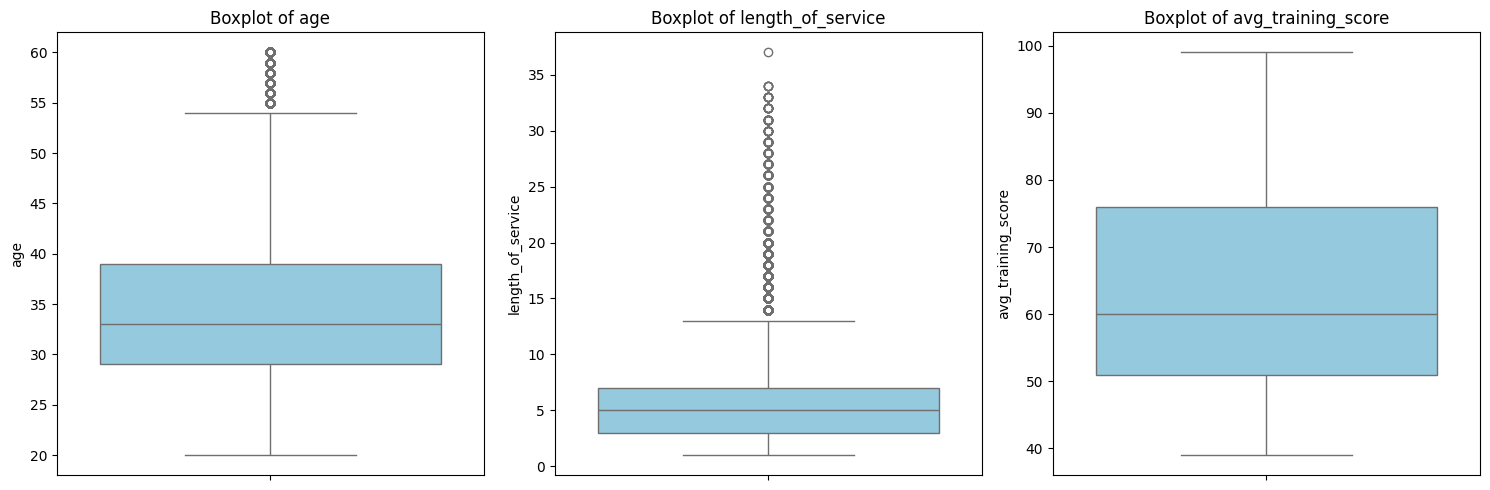

In [12]:
cols_to_plot = ['age', 'length_of_service', 'avg_training_score']

plt.figure(figsize=(15, 5))
for i, col in enumerate(cols_to_plot, 1):
    plt.subplot(1, 3, i)
    sns.boxplot(y=df_train[col], color='skyblue')
    plt.title(f'Boxplot of {col}')
    plt.ylabel(col)

plt.tight_layout()
plt.show()

In [13]:
# Create a copy of the training data to apply outlier handling safely
df_train_clean = df_train.copy()

def cap_outliers(df, column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_boundary = Q1 - 1.5 * IQR
    upper_boundary = Q3 + 1.5 * IQR

    # Cap values exceeding upper or lower boundaries
    df[column] = np.where(df[column] > upper_boundary, upper_boundary,
                          np.where(df[column] < lower_boundary, lower_boundary, df[column]))
    return df

# Cap outliers in 'age' and 'length_of_service'
for col in ['age', 'length_of_service']:
    df_train_clean = cap_outliers(df_train_clean, col)

In [14]:
#verifying if the outliers are all handeled
def find_outliers(column):
    Q1 = df_train_clean[column].quantile(0.25)
    Q3 = df_train_clean[column].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    return df_train_clean[(df_train_clean[column] < lower) | (df_train_clean[column] > upper)]
    return lower,upper

#outliers in age
outliers_age = find_outliers('age')
print("Outliers in age:",len(outliers_age))

#outliers in length_of_service
outliers_length_of_service = find_outliers('length_of_service')
print("Outliers in length_of_service:",len(outliers_length_of_service))

#outliers in avg_training_score
outliers_avg_training_score = find_outliers('avg_training_score')
print("Outliers in avg_training_score:",len(outliers_avg_training_score))

Outliers in age: 0
Outliers in length_of_service: 0
Outliers in avg_training_score: 0


In [15]:
#drop empployee_id
df_train_clean = df_train_clean.drop('employee_id', axis=1)
df_train_clean.head()

,department,region,education,gender,recruitment_channel,no_of_trainings,age,previous_year_rating,length_of_service,KPIs_met >80%,awards_won?,avg_training_score,is_promoted
0,Sales & Marketing,region_7,Master's & above,f,sourcing,1,35.0,5.0,8.0,1,0,49,0
1,Operations,region_22,Bachelor's,m,other,1,30.0,5.0,4.0,0,0,60,0
2,Sales & Marketing,region_19,Bachelor's,m,sourcing,1,34.0,3.0,7.0,0,0,50,0
3,Sales & Marketing,region_23,Bachelor's,m,other,2,39.0,1.0,10.0,0,0,50,0
4,Technology,region_26,Bachelor's,m,other,1,45.0,3.0,2.0,0,0,73,0


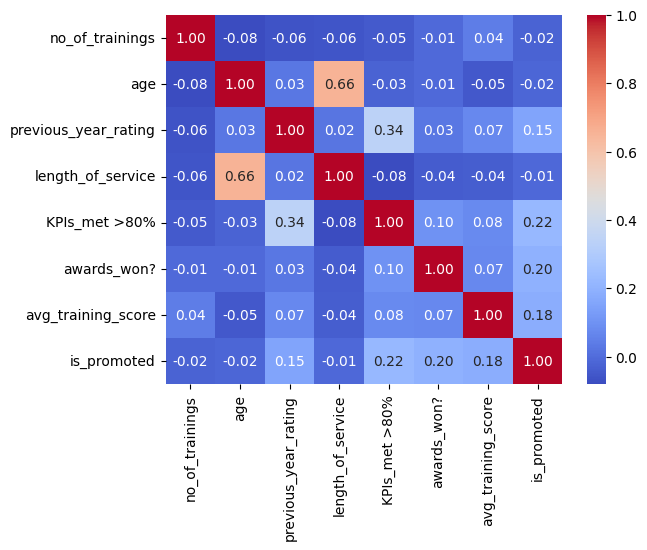

In [16]:
#checking for correlation
sns.heatmap(df_train.drop(columns='employee_id').select_dtypes('number').corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.show()

In [17]:
df_train_clean['is_promoted'].value_counts()

,count
is_promoted,
0,50140
1,4668


In [18]:
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import train_test_split

# Create a fresh, clean copy of df_train to reset any previous mapping runs
df_train_clean = df_train.copy()

# Re-apply outlier capping and drop employee_id
for col in ['age', 'length_of_service']:
    df_train_clean = cap_outliers(df_train_clean, col)
df_train_clean = df_train_clean.drop('employee_id', axis=1, errors='ignore')

# 1. Map Gender directly
gender_mapping = {'m': 1, 'f': 0}
df_train_clean['gender'] = df_train_clean['gender'].map(gender_mapping)

# 2. Map Education directly (Ordinal)
education_mapping = {
    'Below Secondary': 0,
    "Bachelor's": 1,
    "Master's & above": 2
}
df_train_clean['education'] = df_train_clean['education'].map(education_mapping)

# 3. One-Hot Encode remaining nominal categorical columns
nominal_cols = ['department', 'region', 'recruitment_channel']
train_encoded = pd.get_dummies(df_train_clean, columns=nominal_cols, drop_first=True)

# 4. Separate features and target
x = train_encoded.drop('is_promoted', axis=1)
y = train_encoded['is_promoted']

# 5.splitting dataset
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)

# 6.Applying SMOTE on the training set for balancing target
smote = SMOTE(random_state=42)
x_train, y_train = smote.fit_resample(x_train, y_train)

In [19]:
# scale only the continuous columns
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
x_train[['age', 'avg_training_score', 'length_of_service']] = scaler.fit_transform(x_train[['age', 'avg_training_score', 'length_of_service']])
x_test[['age', 'avg_training_score', 'length_of_service']] = scaler.transform(x_test[['age', 'avg_training_score', 'length_of_service']])

In [20]:
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score

In [21]:
#RandomForestClassifier
rf_model = RandomForestClassifier(random_state=42)
rf_model.fit(x_train, y_train)
rf_preds = rf_model.predict(x_test)

rf_accuracy = accuracy_score(y_test, rf_preds)
print(f"Random Forest Accuracy: {rf_accuracy}")
rf_conf_matrix = confusion_matrix(y_test, rf_preds)
print("Random Forest Confusion Matrix:")
print(rf_conf_matrix)
f1 = f1_score(y_test, rf_preds)
print(f"F1 :{f1}")

Random Forest Accuracy: 0.9225506294471811
Random Forest Confusion Matrix:
[[9787  241]
 [ 608  326]]
F1 :0.4343770819453698


In [22]:
#XGBoost
xgb_model = XGBClassifier(random_state=42)
xgb_model.fit(x_train, y_train)
xgb_preds = xgb_model.predict(x_test)

xgb_accuracy = accuracy_score(y_test, xgb_preds)
print(f"XGBoost Accuracy: {xgb_accuracy}")
xgb_conf_matrix = confusion_matrix(y_test, xgb_preds)
print("XGBoost Confusion Matrix:")
print(xgb_conf_matrix)
print(f"F1 :{f1_score(y_test, xgb_preds)}")

XGBoost Accuracy: 0.9290275497172049
XGBoost Confusion Matrix:
[[9819  209]
 [ 569  365]]
F1 :0.48408488063660476


In [23]:
#Logistic Regression
lr_model = LogisticRegression(random_state=4, max_iter=1000)
lr_model.fit(x_train, y_train)
lr_preds = lr_model.predict(x_test)

lr_accuracy = accuracy_score(y_test, lr_preds)
print(f"Logistic Regression Accuracy: {lr_accuracy}")
lr_conf_matrix = confusion_matrix(y_test, lr_preds)
print("Logistic Regression Confusion Matrix:")
print(lr_conf_matrix)
print(f"F1 :{f1_score(y_test, lr_preds)}")

Logistic Regression Accuracy: 0.8955482576172231
Logistic Regression Confusion Matrix:
[[9438  590]
 [ 555  379]]
F1 :0.3983184445612191


In [24]:
from sklearn.model_selection import RandomizedSearchCV

# Define the parameter grid for XGBoost
param_dist = {
    'n_estimators': [100, 200, 300, 400],
    'learning_rate': [0.01, 0.05, 0.1, 0.2],
    'max_depth': [3, 4, 5, 6, 8],
    'min_child_weight': [1, 3, 5, 7],
    'subsample': [0.6, 0.7, 0.8, 0.9, 1.0],
    'colsample_bytree': [0.6, 0.7, 0.8, 0.9, 1.0],
    'gamma': [0, 0.1, 0.2, 0.3, 0.4]
}

# Initialize XGBoost classifier
xgb = XGBClassifier(random_state=42, use_label_encoder=False, eval_metric='logloss')

# Set up RandomizedSearchCV
xgb_random = RandomizedSearchCV(
    estimator=xgb,
    param_distributions=param_dist,
    n_iter=10,
    scoring='f1',
    cv=3,
    verbose=1,
    random_state=42,
    n_jobs=-1
)

# Fit RandomizedSearchCV
print("Starting Randomized Search...")
xgb_random.fit(x_train, y_train)

# Get best parameters
best_params = xgb_random.best_params_
print("Best Parameters Found:", best_params)

Starting Randomized Search...
Fitting 3 folds for each of 10 candidates, totalling 30 fits


/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [07:50:06] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


Best Parameters Found: {'subsample': 0.6, 'n_estimators': 400, 'min_child_weight': 3, 'max_depth': 5, 'learning_rate': 0.2, 'gamma': 0.4, 'colsample_bytree': 0.7}


In [25]:
# Fit new parameters in XGBoost using the best parameters found
best_xgb_model = XGBClassifier(
    n_estimators=best_params['n_estimators'],
    learning_rate=best_params['learning_rate'],
    max_depth=best_params['max_depth'],
    min_child_weight=best_params['min_child_weight'],
    subsample=best_params['subsample'],
    colsample_bytree=best_params['colsample_bytree'],
    gamma=best_params['gamma'],
    random_state=42,
    use_label_encoder=False,
    eval_metric='logloss'
)

best_xgb_model.fit(x_train, y_train)
best_xgb_preds = best_xgb_model.predict(x_test)

best_xgb_accuracy = accuracy_score(y_test, best_xgb_preds)
best_xgb_f1 = f1_score(y_test, best_xgb_preds)
print(f"Best XGBoost Accuracy: {best_xgb_accuracy}")
print(f"Best XGBoost F1 Score: {best_xgb_f1}")

/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [07:50:13] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


Best XGBoost Accuracy: 0.9351395730706076
Best XGBoost F1 Score: 0.4910522548317824


In [26]:
test = pd.read_csv(testing_data)
test.head()

,employee_id,department,region,education,gender,recruitment_channel,no_of_trainings,age,previous_year_rating,length_of_service,KPIs_met >80%,awards_won?,avg_training_score
0,8724,Technology,region_26,Bachelor's,m,sourcing,1,24,NaN,1,1,0,77
1,74430,HR,region_4,Bachelor's,f,other,1,31,3.0,5,0,0,51
2,72255,Sales & Marketing,region_13,Bachelor's,m,other,1,31,1.0,4,0,0,47
3,38562,Procurement,region_2,Bachelor's,f,other,3,31,2.0,9,0,0,65
4,64486,Finance,region_29,Bachelor's,m,sourcing,1,30,4.0,7,0,0,61


In [27]:
test.isna().sum()

,0
employee_id,0
department,0
region,0
education,1034
gender,0
recruitment_channel,0
no_of_trainings,0
age,0
previous_year_rating,1812
length_of_service,0


In [28]:
# Save the employee_id for submission purposes before dropping
test_employee_id = test['employee_id']

# 1. Create a clean copy and handle missing values using training parameters
test_clean = test.copy()
test_clean['education'] = test_clean['education'].fillna(education_mode)
test_clean['previous_year_rating'] = test_clean['previous_year_rating'].fillna(rating_median)

# 2. Cap outliers in 'age' and 'length_of_service' using the cap_outliers function
for col in ['age', 'length_of_service']:
    test_clean = cap_outliers(test_clean, col)

# Drop employee_id
test_clean = test_clean.drop('employee_id', axis=1, errors='ignore')

# 3. Map Gender and Education
test_clean['gender'] = test_clean['gender'].map(gender_mapping)
test_clean['education'] = test_clean['education'].map(education_mapping)

# 4. One-Hot Encode nominal variables
test_encoded = pd.get_dummies(test_clean, columns=nominal_cols, drop_first=True)

# 5. Align test columns with the training features (x) to ensure identical feature structure
# This adds missing columns with False/0 and drops any columns not present in training data
x_test_final = test_encoded.reindex(columns=x.columns, fill_value=0)

# 6. Scale continuous columns using the pre-fitted scaler
x_test_final[['age', 'avg_training_score', 'length_of_service']] = scaler.transform(x_test_final[['age', 'avg_training_score', 'length_of_service']])

# Verify the final preprocessed test shape matches training shape
print("Preprocessed training features shape:", x_train.shape)
print("Preprocessed test features shape:", x_test_final.shape)

# Display the first few rows of the final processed test features
display(x_test_final.head())

Preprocessed training features shape: (80224, 52)
Preprocessed test features shape: (23490, 52)


,education,gender,no_of_trainings,age,previous_year_rating,length_of_service,KPIs_met >80%,awards_won?,avg_training_score,department_Finance,...,region_region_33,region_region_34,region_region_4,region_region_5,region_region_6,region_region_7,region_region_8,region_region_9,recruitment_channel_referred,recruitment_channel_sourcing
0,1,1,1,-1.464870,3.0,-1.339294,1,0,0.703586,False,...,False,False,False,False,False,False,False,False,False,True
1,1,0,1,-0.490549,3.0,-0.151809,0,0,-1.091809,False,...,False,False,True,False,False,False,False,False,False,False
2,1,1,1,-0.490549,1.0,-0.448680,0,0,-1.368024,False,...,False,False,False,False,False,False,False,False,False,False
3,1,0,3,-0.490549,2.0,1.035677,0,0,-0.125058,False,...,False,False,False,False,False,False,False,False,False,False
4,1,1,1,-0.629737,4.0,0.441934,0,0,-0.401273,True,...,False,False,False,False,False,False,False,False,False,True


In [29]:
# Generate predictions using the best tuned XGBoost model
test_predictions = best_xgb_model.predict(x_test_final)

# Create a submission DataFrame
submission_df = pd.DataFrame({
    'employee_id': test_employee_id,
    'is_promoted': test_predictions
})

# Print the prediction distribution
print("Predicted Class Distribution for Test Data:")
print(submission_df['is_promoted'].value_counts())

# Display preview of submission
display(submission_df.head())

# Save predictions to CSV
submission_df.to_csv('xgb_submission.csv', index=False)
print("\nSubmission file successfully saved as 'xgb_submission.csv'!")

Predicted Class Distribution for Test Data:
is_promoted
0    22568
1      922
Name: count, dtype: int64


,employee_id,is_promoted
0,8724,0
1,74430,0
2,72255,0
3,38562,0
4,64486,0



Submission file successfully saved as 'xgb_submission.csv'!


In [30]:
import os

# 1. Define the folder where you want to save the submission file
# E.g., Use '/content/drive/MyDrive/DSA/' or any folder of your choice
custom_folder = '/content/drive/MyDrive/DSA/Anitha miss/Analytics Vidhya/'

# 2. Create the directory if it does not exist
os.makedirs(custom_folder, exist_ok=True)

# 3. Define the full output path
custom_output_path = os.path.join(custom_folder, 'xgb_submission.csv')

# 4. Save the submission DataFrame to the chosen folder
submission_df.to_csv(custom_output_path, index=False)
print(f"Submission file successfully saved to your chosen folder:\n{custom_output_path}")

Submission file successfully saved to your chosen folder:
/content/drive/MyDrive/DSA/Anitha miss/Analytics Vidhya/xgb_submission.csv
